# Mini-project 1: Handwritten Digit Recognizer

Self-contained notebook: downloads MNIST, trains a CNN, evaluates it and saves `models/mnist_cnn.keras`.
Runtime: about 2 minutes on a CPU. Needs internet on the first run. Part of the [ml-mini-projects](README.md) set.

In [1]:
import os, gzip, json, time, random, urllib.request, urllib.parse, urllib.error
import concurrent.futures as cf
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)

ROOT = Path.cwd()
DATA, IMG, MODELS = ROOT / "data", ROOT / "images", ROOT / "models"
for p in (DATA, IMG, MODELS):
    p.mkdir(exist_ok=True)

RESULTS = {}   # collected metrics -> saved as JSON at the end
GH = "https://raw.githubusercontent.com/"

def download(url, dest, retries=3):
    """Download url to dest (skipped if the file is already cached)."""
    dest = Path(dest)
    if dest.exists() and dest.stat().st_size > 0:
        return dest
    dest.parent.mkdir(parents=True, exist_ok=True)
    for attempt in range(retries):
        try:
            with urllib.request.urlopen(url, timeout=60) as r:
                payload = r.read()
            tmp = dest.with_suffix(dest.suffix + ".part")
            tmp.write_bytes(payload)
            tmp.replace(dest)
            return dest
        except Exception:
            if attempt == retries - 1:
                raise
            time.sleep(2 * (attempt + 1))

def save_fig(name):
    plt.savefig(IMG / name, dpi=130, bbox_inches="tight")

print("TensorFlow", tf.__version__, "| NumPy", np.__version__)

I0000 00:00:1793622093.750704     187 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1793622114.629515     187 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0 | NumPy 2.5.3


# Handwritten Digit Recognizer (MNIST + CNN)

**MNIST** has 70,000 grayscale 28x28 images of handwritten digits (60,000 for training, 10,000 for testing).
A **convolutional neural network** slides small learnable filters over the image, so it can pick up strokes and
curves wherever they appear, which is why CNNs beat plain dense networks on images.

The files are the original MNIST `.gz` files in IDX format, fetched from a GitHub mirror. The parser below is
only a few lines.

In [2]:
MNIST_BASE = "https://raw.githubusercontent.com/fgnt/mnist/master/"
MNIST_FILES = {
    "x_train": "train-images-idx3-ubyte.gz",
    "y_train": "train-labels-idx1-ubyte.gz",
    "x_test":  "t10k-images-idx3-ubyte.gz",
    "y_test":  "t10k-labels-idx1-ubyte.gz",
}

def read_idx(path):
    """Parse an (gzipped) IDX file into a numpy uint8 array."""
    with gzip.open(path, "rb") as f:
        raw = f.read()
    assert raw[0] == 0 and raw[1] == 0 and raw[2] == 8, "unexpected IDX header"
    ndim = raw[3]
    dims = [int.from_bytes(raw[4 + 4 * i: 8 + 4 * i], "big") for i in range(ndim)]
    return np.frombuffer(raw, dtype=np.uint8, offset=4 + 4 * ndim).reshape(dims)

mnist = {k: read_idx(download(MNIST_BASE + v, DATA / "mnist" / v)) for k, v in MNIST_FILES.items()}
x_train, y_train, x_test, y_test = (mnist[k] for k in ("x_train", "y_train", "x_test", "y_test"))

assert x_train.shape == (60000, 28, 28) and x_test.shape == (10000, 28, 28)
assert len(y_train) == 60000 and len(y_test) == 10000
print("train:", x_train.shape, "test:", x_test.shape, "| pixel range:", x_train.min(), "-", x_train.max())
print("train label counts:", np.bincount(y_train).tolist())
print("test  label counts:", np.bincount(y_test).tolist())

train: (60000, 28, 28) test: (10000, 28, 28) | pixel range: 0 - 255
train label counts: [5923, 6742, 5958, 6131, 5842, 5421, 5918, 6265, 5851, 5949]
test  label counts: [980, 1135, 1032, 1010, 982, 892, 958, 1028, 974, 1009]


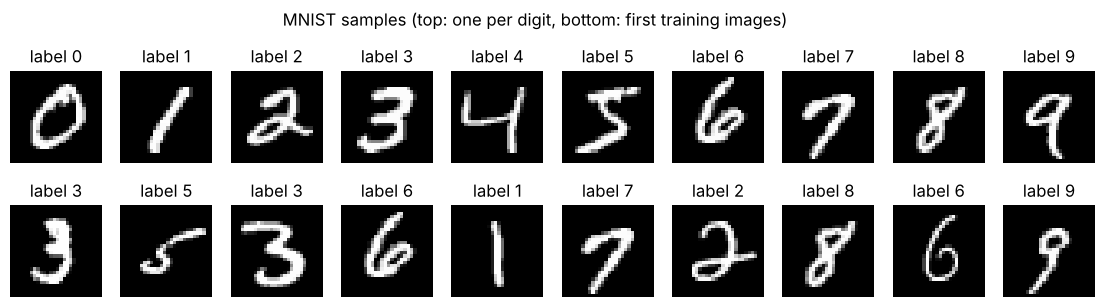

In [3]:
fig, axes = plt.subplots(2, 10, figsize=(14, 3.2))
for d, ax in zip(range(10), axes[0]):
    ax.imshow(x_train[np.where(y_train == d)[0][0]], cmap="gray"); ax.set_title(f"label {d}"); ax.axis("off")
for ax, i in zip(axes[1], range(10, 20)):
    ax.imshow(x_train[i], cmap="gray"); ax.set_title(f"label {y_train[i]}"); ax.axis("off")
plt.suptitle("MNIST samples (top: one per digit, bottom: first training images)", y=1.04)
save_fig("mnist_samples.png"); plt.show()

### Build and train the CNN
Pixels are scaled to 0-1 and given a channel axis. The network is two conv + pooling blocks followed by a small
dense classifier with dropout (dropout randomly switches off units during training to reduce overfitting).
10% of the training set is held out for validation; the 10,000-image test set is used only once at the end.

In [4]:
x_train_f = (x_train.astype("float32") / 255.0)[..., None]
x_test_f = (x_test.astype("float32") / 255.0)[..., None]

def build_mnist_cnn():
    return keras.Sequential([
        layers.Input((28, 28, 1)),
        layers.Conv2D(32, 3, activation="relu"),
        layers.MaxPooling2D(),
        layers.Conv2D(64, 3, activation="relu"),
        layers.MaxPooling2D(),
        layers.Flatten(),
        layers.Dropout(0.3),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(10, activation="softmax"),
    ], name="mnist_cnn")

mnist_model = build_mnist_cnn()
mnist_model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
mnist_model.summary()

MNIST_EPOCHS = 8
t0 = time.time()
mnist_hist = mnist_model.fit(x_train_f, y_train, validation_split=0.1,
                             epochs=MNIST_EPOCHS, batch_size=128, verbose=2)
mnist_seconds = time.time() - t0
print(f"training took {mnist_seconds:.0f}s")

Model: "mnist_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/8


... (12 outputs left out)

422/422 - 9s - 21ms/step - accuracy: 0.9878 - loss: 0.0374 - val_accuracy: 0.9905 - val_loss: 0.0350


Epoch 8/8


422/422 - 10s - 24ms/step - accuracy: 0.9899 - loss: 0.0318 - val_accuracy: 0.9923 - val_loss: 0.0302


training took 81s


### Evaluate on the untouched test set

In [5]:
mnist_test_loss, mnist_test_acc = mnist_model.evaluate(x_test_f, y_test, verbose=0)
mnist_probs = mnist_model.predict(x_test_f, verbose=0)
mnist_pred = mnist_probs.argmax(1)
n_err = int((mnist_pred != y_test).sum())
print(f"MNIST test accuracy: {mnist_test_acc:.4f}  ({n_err} errors out of {len(y_test)})  | test loss {mnist_test_loss:.4f}")
print()
print(classification_report(y_test, mnist_pred, digits=4))

RESULTS["mnist"] = {
    "test_accuracy": float(mnist_test_acc), "test_loss": float(mnist_test_loss),
    "test_errors": n_err, "test_size": int(len(y_test)),
    "epochs": MNIST_EPOCHS, "parameters": int(mnist_model.count_params()),
    "train_seconds": round(mnist_seconds, 1),
    "final_train_acc": float(mnist_hist.history["accuracy"][-1]),
    "final_val_acc": float(mnist_hist.history["val_accuracy"][-1]),
    "per_class_recall": {str(i): float(r) for i, r in enumerate(
        confusion_matrix(y_test, mnist_pred).diagonal() / np.bincount(y_test))},
}

MNIST test accuracy: 0.9923  (77 errors out of 10000)  | test loss 0.0239

              precision    recall  f1-score   support

           0     0.9879    0.9980    0.9929       980
           1     0.9921    0.9982    0.9952      1135
           2     0.9922    0.9922    0.9922      1032
           3     0.9941    0.9931    0.9936      1010
           4     0.9909    0.9990    0.9949       982
           5     0.9899    0.9910    0.9905       892
           6     0.9979    0.9885    0.9932       958
           7     0.9893    0.9922    0.9908      1028
           8     0.9938    0.9887    0.9913       974
           9     0.9950    0.9812    0.9880      1009

    accuracy                         0.9923     10000
   macro avg     0.9923    0.9922    0.9923     10000
weighted avg     0.9923    0.9923    0.9923     10000



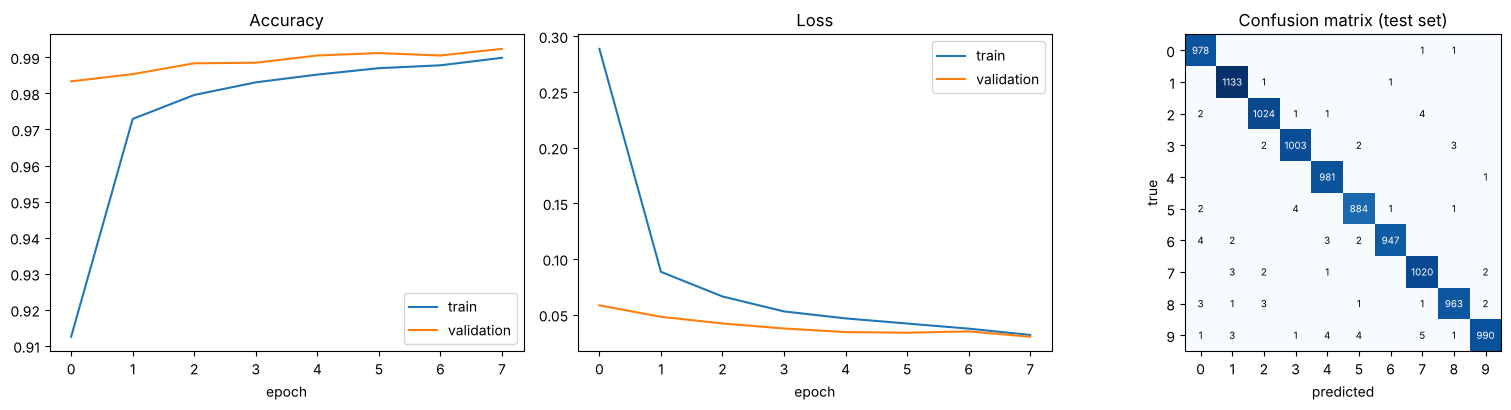

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
h = mnist_hist.history
axes[0].plot(h["accuracy"], label="train"); axes[0].plot(h["val_accuracy"], label="validation")
axes[0].set_title("Accuracy"); axes[0].set_xlabel("epoch"); axes[0].legend()
axes[1].plot(h["loss"], label="train"); axes[1].plot(h["val_loss"], label="validation")
axes[1].set_title("Loss"); axes[1].set_xlabel("epoch"); axes[1].legend()

cm = confusion_matrix(y_test, mnist_pred)
axes[2].imshow(cm, cmap="Blues")
axes[2].set_title("Confusion matrix (test set)"); axes[2].set_xlabel("predicted"); axes[2].set_ylabel("true")
axes[2].set_xticks(range(10)); axes[2].set_yticks(range(10))
for i in range(10):
    for j in range(10):
        if cm[i, j]:
            axes[2].text(j, i, cm[i, j], ha="center", va="center",
                         color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=7)
plt.tight_layout(); save_fig("mnist_training_and_confusion.png"); plt.show()

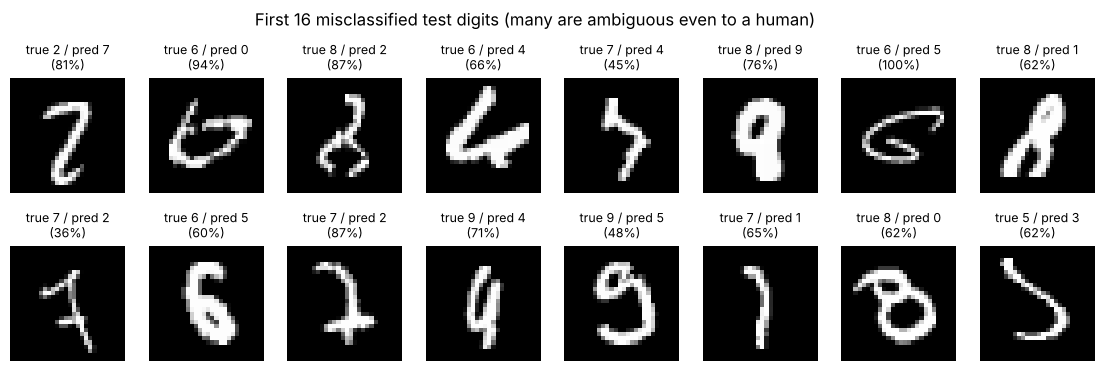

In [7]:
wrong = np.where(mnist_pred != y_test)[0]
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for ax, i in zip(axes.ravel(), wrong[:16]):
    ax.imshow(x_test[i], cmap="gray"); ax.axis("off")
    ax.set_title(f"true {y_test[i]} / pred {mnist_pred[i]}\n({mnist_probs[i].max():.0%})", fontsize=9)
plt.suptitle(f"First {min(16, len(wrong))} misclassified test digits (many are ambiguous even to a human)", y=1.02)
save_fig("mnist_errors.png"); plt.show()

### Try it on your own digit
`predict_digit_from_image` follows MNIST conventions: white digit on black, cropped, scaled to fit 20x20 and
centred in a 28x28 frame. The demo below uses a real MNIST test digit saved as a black-on-white PNG, to prove the
pipeline works end to end. Point it at your own drawing for a real test (a thick dark pen on white paper works best).

In [8]:
def predict_digit_from_image(path, model=mnist_model):
    img = Image.open(path).convert("L")
    if np.asarray(img).mean() > 127:          # dark ink on light paper -> flip to MNIST style
        img = ImageOps.invert(img)
    ys, xs = np.where(np.asarray(img) > 40)
    if len(xs) == 0:
        raise ValueError("no ink found in the image")
    img = img.crop((xs.min(), ys.min(), xs.max() + 1, ys.max() + 1))
    w, h = img.size
    s = 20 / max(w, h)
    img = img.resize((max(1, round(w * s)), max(1, round(h * s))), Image.LANCZOS)
    canvas = Image.new("L", (28, 28), 0)
    canvas.paste(img, ((28 - img.size[0]) // 2, (28 - img.size[1]) // 2))
    x = (np.asarray(canvas, dtype="float32") / 255.0)[None, ..., None]
    probs = model.predict(x, verbose=0)[0]
    return int(probs.argmax()), float(probs.max())

demo_idx = 7
demo_path = IMG / "demo_digit.png"
Image.fromarray(255 - x_test[demo_idx]).resize((280, 280), Image.NEAREST).save(demo_path)
pred, conf = predict_digit_from_image(demo_path)
print(f"true label: {y_test[demo_idx]} | predicted: {pred} (confidence {conf:.1%})")

mnist_model.save(MODELS / "mnist_cnn.keras")

true label: 9 | predicted: 9 (confidence 98.3%)


In [9]:
(ROOT / "results_mnist.json").write_text(json.dumps(RESULTS, indent=2))
m = RESULTS["mnist"]
print(f"MNIST CNN test accuracy {m['test_accuracy']:.2%} ({m['test_errors']} errors / {m['test_size']})")
print("\nSaved: results_mnist.json, images/mnist_*.png, models/mnist_cnn.keras")

MNIST CNN test accuracy 99.23% (77 errors / 10000)

Saved: results_mnist.json, images/mnist_*.png, models/mnist_cnn.keras
